### PDAC and neural invasion - ligand-receptor communication in regions, nerve zones, NI groups and between cell types (mp_pdac04)

**Paper**: Chen MM, Gao Q, Ning H, Chen K, Gao Y, Yu M, Liu CQ, Zhou W, Pan J, Wei L, Dou W, Zhang D, Zhu L, Zhang Q, Chen R, Zhang Z. *Integrated single-cell and spatial transcriptomics uncover distinct cellular subtypes involved in neural invasion in pancreatic cancer.* Cancer Cell. 2025 Sep 8;43(9):1656-1676.e10. doi: [10.1016/j.ccell.2025.06.020](https://doi.org/10.1016/j.ccell.2025.06.020). PMID: 40680743.

Code: [github.com/PDAC-zhanglab/PDAC](https://github.com/PDAC-zhanglab/PDAC) (R figure scripts; copy in pdac/data/github_PDAC-zhanglab) - Data: GEO SuperSeries [GSE278694](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278694) = [GSE278687](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278687) (Visium, 21 sections) + [GSE278688](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278688) (scRNA) + [GSE278689](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278689) (FFPE snRNA) + GSE300435 (scTCR); raw reads GSA HRA008568.

LIANA+ bivariate (spatial co-expression of ligand and receptor), cell-type-resolved sender -> receiver scores and the reference rank_aggregate, as in **mp_heart_dvlp04** / **mp_lymphoid04**, **per region** (mp_pdac01), **per subregion** (mp_pdac03), **per NI group** (low vs high) and, new here, **per nerve zone** (nerve, juxta- and peri-neural spots of invaded vs non-invaded nerves; mp_pdac03).

**Question**: which ligand-receptor (LR) pairs are spatially active around **invaded** vs **non-invaded** nerves, and between which cell types? The paper used **COMMOT** with **CellChatDB** (200 um range, per sample; Figures 4F / 4G: senders in non-invaded nerves, receivers in the juxta-neural niches, e.g. CXCL12 -> CXCR4), **CellChat** (TGF-beta network towards S02_Schwann-TGFBI, Figure 6) and **NicheNet** (ligands driving S02_Schwann-TGFBI: TGFB1, HGF). Here LIANA is run with the **consensus** resource and with **CellChatDB**.

#### Libs: **src/libs**

- **single_cell_lib**
  - Class **SingleCell**: generic Scanpy, Squidpy, cell2location and LIANA methods
  - **DEFAULT_PARAMS**
- **single_cell_pdac_lib** (new)
  - Class **SingleCellPDAC(SingleCell)**: PDAC methods (sections, NI status and platforms, re-derived subclusters, RCTD / cell2location abundances, regions named after the paper's niches, sections as replicates for high vs low NI, nerve spots / invasion / rings)
  - **PDAC_PARAMS**, **PDAC_SUBCLUSTERS** (marker sets of the paper's subclusters), **PDAC_GENES** (26 PDAC / NI genes), **PDAC_NI_GENES**, **PDAC_NERVE_GENES**, **PAPER_NICHES**, **PDAC_FILES** (one file registry per notebook: 'pdac01' ... 'pdac04')

**Programs: src/programs**: pdac_build_h5ad.py (GEO -> h5ad), pdac_reference_subclusters.py (subclusters), run_rctd_pdac.R (RCTD), run_c2l_pdac.py (cell2location, GPU).

| section | content |
|---|---|
| 1 | spots, regions, subregions, NI groups, nerve zones, abundances, signatures |
| 2 | spatial weights (Gaussian kernel per section) |
| 3 | LIANA bivariate (consensus; CellChatDB): global Moran's R and local scores |
| 4 | LR pairs enriched in each region and subregion |
| 5 | LR pairs enriched in each nerve zone (invaded vs non-invaded; Figure 4F / 4G analogue) |
| 6 | LR pairs by NI group (low vs high; all sections and CytAssist only) |
| 7 | between cell types: sender -> receiver (whole tissue, per group) |
| 8 | TGF-beta (and HGF) towards S02_Schwann-TGFBI; CXCL12 -> CXCR4 around non-invaded nerves |
| 9 | reference LIANA (rank_aggregate) + cell-type co-localisation |
| 10 | consensus per region / nerve zone; tables |

Figures and tables have the prefix **pdac04_**.

### Critique of the analysis and how it is handled

- **Visium spots mix 5-15 cells**: a bivariate local score says ligand and receptor are co-expressed in a ~200 um neighbourhood (bandwidth 1.1 spot spacings, rings 1-2: the paper's COMMOT range), not that two cells signal.
- **21 sections, 3 platforms**: the spatial kernel is per section; genes = the 17,368 of the three panels. NI contrasts are repeated on the CytAssist sections.
- **Cell-type attribution** splits each spot's counts by abundance x reference signature (**calc_celltype_expr**); with 258 Schwann reference cells the S01-S03 signatures are noisy.
- **CellChatDB vs consensus**: CellChatDB carries pathway annotations (e.g. TGFb, CXCL, SEMA3) and complexes used by the paper; consensus is LIANA's default union.
- **Statistics**: neighbouring spots are not independent; groups and links are ranked by effect sizes (AUROC, z, ratio).

## Loading packages

In [1]:
import os, sys
from pathlib import Path
from importlib.metadata import version
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import gc

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42          # editable text in PDFs
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 90}   # inline display only; files are saved at 300 dpi
import plotly.io as pio
pio.renderers.default = "notebook_connected"

ROOT0 = Path('/home/flavio/uv/cell_cell_communication')
ROOT_SRC = ROOT0 / 'src'
if str(ROOT_SRC) not in sys.path:
    sys.path.append(str(ROOT_SRC))

from libs.single_cell_pdac_lib import (SingleCellPDAC, PDAC_PARAMS, PDAC_SUBCLUSTERS, PDAC_GENES, PDAC_NI_GENES,
                                       PDAC_NERVE_GENES, PAPER_NICHES, PDAC_FILES)
from libs.single_cell_lib import cmap_byr, cmap_lbwr
from libs.matplotlib_figure_style import apply_figure_style
from libs.Basic import create_dir

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 250)
pd.set_option('display.max_rows', 200)
import liana as li
print({p: version(p) for p in ['liana', 'scanpy', 'anndata', 'plotly']})

{'liana': '2.1.1', 'scanpy': '1.12.4', 'anndata': '0.13.4', 'plotly': '7.1.0'}


## Parameters

In [2]:
force=False
verbose=False

apply_figure_style()
scp = SingleCellPDAC(ROOT0, analysis='pdac04')
scp.set_params(subregion_skip=tuple(scp.unassigned_regions()))     # spots without deconvolution: not a region of LR analysis
print(scp)
print({k: scp.params[k] for k in ['liana_resource', 'liana_bandwidth_spots', 'liana_nz_prop', 'lr_group_min_auroc', 'lr_display_exclude']})
print('CellChatDB in liana:', 'cellchatdb' in li.resource.show_resources())
scp.calc_df_files()

SingleCellPDAC(project='pdac', adata=None, symbol_col='symbol', sample_col='section')
{'liana_resource': 'consensus', 'liana_bandwidth_spots': 1.1, 'liana_nz_prop': 0.05, 'lr_group_min_auroc': 0.65, 'lr_display_exclude': '(?i)^(HLA-|H2-)|^(B2M|LCK|GNAS|GNAI2|GNB1|ARF1|CALM[123]|RIMS1|SPTBN2|SHANK1|PTPN6)\\^'}
CellChatDB in liana: True
Out[2]: 
                          key  ... exists
0                      visium  ...   True
1                   reference  ...   True
2                    sections  ...   True
3                  visium_raw  ...   True
4                     geo_dir  ...   True
5                 geo_samples  ...   True
6                      sc_dir  ...   True
7                      sn_dir  ...   True
8                  st_tar_dir  ...   True
9           subcluster_labels  ...   True
10                   rctd_dir  ...   True
11               rctd_weights  ...   True
12                c2l_ref_dir  ...   True
13                c2l_map_dir  ...   True
14                    c2

,key,root,name,path,exists
0,visium,data,pdac_visium_21sections.h5ad,/home/flavio/uv/cell_cell_communication/pdac/data/pdac_visium_21sections.h5ad,True
1,reference,data,pdac_sc_sn_reference.h5ad,/home/flavio/uv/cell_cell_communication/pdac/data/pdac_sc_sn_reference.h5ad,True
2,sections,data,pdac_sections.tsv,/home/flavio/uv/cell_cell_communication/pdac/data/pdac_sections.tsv,True
3,visium_raw,data,visium,/home/flavio/uv/cell_cell_communication/pdac/data/visium,True
4,geo_dir,data,geo,/home/flavio/uv/cell_cell_communication/pdac/data/geo,True
5,geo_samples,data,geo/GSE278694_samples_soft.txt,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278694_samples_soft.txt,True
6,sc_dir,data,geo/GSE278688,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278688,True
7,sn_dir,data,geo/GSE278689,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278689,True
8,st_tar_dir,data,geo/GSE278687/raw,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278687/raw,True
9,subcluster_labels,result,pdac01_reference_subclusters.tsv,/home/flavio/uv/cell_cell_communication/pdac/results/pdac01_reference_subclusters.tsv,True


### 1. Spots, regions, subregions, NI groups, nerve zones and abundances

In [3]:
df_regions = scp.read_tsv('region_labels', verbose=verbose)
source = df_regions['abundance_source'].iloc[0]
adata_map = scp.read_h5ad('visium', set_self=False)
adata_map = scp.remove_mt_genes(adata_map)
if source == 'c2l':
    a_map = scp.read_h5ad_slots('c2l_map', skip=('layers',))
    adata_map.obsm['q05_cell_abundance_w_sf'] = pd.DataFrame(a_map.obsm['q05_cell_abundance_w_sf'], index=a_map.obs_names).loc[adata_map.obs_names]
    adata_map.uns['mod'] = a_map.uns['mod']; del a_map
d = df_regions.set_index('barcode').loc[adata_map.obs_names]
for c in ('region_cluster', 'region_label', 'region_name', 'niche'):
    adata_map.obs[c] = pd.Categorical(d[c].astype(str).values)
region_name = dict(zip(d.region_label.astype(str), d.region_name.astype(str)))
df_abund = scp.get_abundance(adata_map, source=source)
df_share = scp.shares(df_abund)
df_nerve = scp.read_tsv('nerve_spots').set_index('barcode').loc[adata_map.obs_names]
z = df_nerve.nerve_zone.fillna('').astype(str)
st = df_nerve.ring_status.fillna('').astype(str)
adata_map.obs['nerve_zone_status'] = np.where(z != '', z + ' (' + st + ')', '')

adata_ref = scp.read_h5ad('reference', set_self=False, backed='r')
adata_ref_dec = scp.reference_for_deconvolution(adata_ref)
df_sig = scp.reference_signatures_symbols(adata_ref_dec, summary='means')
print("signatures:", df_sig.attrs['source'], df_sig.shape)

adata_expr = scp.prepare_expression(adata_map)
subs, _ = scp.run_subregions(adata_expr, force=False, verbose=verbose)
celltypes = [c for c in df_abund.columns if c in df_sig.columns]
df_sub03 = scp.read_tsv('subregion_table_pdac03', verbose=verbose)
sub_supported = df_sub03.loc[df_sub03.status.str.startswith('supported'), 'sub_region_id'].tolist()
adata_expr.obs['nerve_zone_status'] = adata_map.obs.loc[adata_expr.obs_names, 'nerve_zone_status'].values
groups = {'region': scp._groups(adata_expr, 'region_label', skip=set(scp.params['subregion_skip'])),
          'subregion': scp._groups(adata_expr, 'sub_region_id'),
          'ni_status': scp._groups(adata_expr, 'ni_status'),
          'nerve_zone': scp._groups(adata_expr, 'nerve_zone_status', skip={''})}
sections_rep = scp.representative_sections()
del subs, adata_map; gc.collect()          # labels are in adata_expr.obs; frees ~6 GB before LIANA
print(adata_expr.shape, '|', len(celltypes), 'cell types |', {k: v.nunique() for k, v in groups.items()})
groups['nerve_zone'].value_counts()

dropped (< 25 tissue cells): ['Platelet']
reference for deconvolution: 56,632 of 141,683 tissue cells, 42 cell types
signatures: mean_counts (30053, 42)
(81846, 17368) | 42 cell types | {'region': 26, 'subregion': 147, 'ni_status': 2, 'nerve_zone': 6}
Out[3]: 
nerve_zone_status
peri-neural (non-invaded)     3543
juxta-neural (non-invaded)    1810
peri-neural (invaded)         1017
nerve (non-invaded)            870
juxta-neural (invaded)         455
nerve (invaded)                103
Name: count, dtype: int64


nerve_zone_status
peri-neural (non-invaded)     3543
juxta-neural (non-invaded)    1810
peri-neural (invaded)         1017
nerve (non-invaded)            870
juxta-neural (invaded)         455
nerve (invaded)                103
Name: count, dtype: int64

### 2. Spatial weights

Gaussian kernel **w = exp(-d^2 / 2bw^2)**, **bw = liana_bandwidth_spots x spot spacing**, per section, self weight 1, weights < **liana_cutoff** removed.

In [4]:
df_w = scp.spatial_weights(adata_expr, force=force, verbose=verbose)
W = adata_expr.obsp['spatial_connectivities']
df_w.groupby('library').mean_neighbours_incl_self.first().describe()

Out[4]: 
count    21.000000
mean     18.033333
std       0.542525
min      16.500000
25%      17.900000
50%      18.300000
75%      18.400000
max      18.500000
Name: mean_neighbours_incl_self, dtype: float64


count    21.000000
mean     18.033333
std       0.542525
min      16.500000
25%      17.900000
50%      18.300000
75%      18.400000
max      18.500000
Name: mean_neighbours_incl_self, dtype: float64

### 3. LIANA bivariate: consensus and CellChatDB

**li.mt.bivariate**: global Moran's R (permutation p, BH FDR) and the local cosine score of every pair at every spot; ligand and receptor (all complex subunits) in >= **liana_nz_prop** of the spots. Cached in **pdac/results**.

In [5]:
df_inter, adata_lr = scp.liana_bivariate(adata_expr, resource_name='consensus', fname='liana_bivariate', fname_global='liana_global',
                                         force=force, verbose=verbose)
df_lr_sig = scp.lr_significant(df_inter)
df_inter_cc, adata_lr_cc = scp.liana_bivariate(adata_expr, resource_name='cellchatdb', fname='liana_bivariate_cellchat',
                                               fname_global='liana_global_cellchat', force=force, verbose=verbose)
df_lr_sig_cc = scp.lr_significant(df_inter_cc)
print(f"consensus: {len(df_inter)} pairs tested, {len(df_lr_sig)} significant | CellChatDB: {len(df_inter_cc)} tested, {len(df_lr_sig_cc)} significant")
df_lr_sig[['ligand', 'receptor', 'ligand_props', 'receptor_props', 'morans', 'morans_fdr']].head(20).round(3)

consensus: 2377 pairs tested, 1768 significant | CellChatDB: 1014 tested, 750 significant
Out[5]: 
                        ligand      receptor  ...  morans  morans_fdr
interaction                                   ...                    
LAMB3^ITGA3_ITGB1        LAMB3   ITGA3_ITGB1  ...   0.308         0.0
LAMC2^ITGA3_ITGB1        LAMC2   ITGA3_ITGB1  ...   0.301         0.0
LAMB3^ITGA6_ITGB4        LAMB3   ITGA6_ITGB4  ...   0.274         0.0
LAMB3^ITGA2_ITGB1        LAMB3   ITGA2_ITGB1  ...   0.272         0.0
LAMC2^ITGA2_ITGB1        LAMC2   ITGA2_ITGB1  ...   0.269         0.0
SPINT1^ST14             SPINT1          ST14  ...   0.265         0.0
LAMC2^ITGA6_ITGB4        LAMC2   ITGA6_ITGB4  ...   0.258         0.0
THBS1^LRP1               THBS1          LRP1  ...   0.253         0.0
CCN2^LRP1                 CCN2          LRP1  ...   0.252         0.0
COL11A1^ITGA11_ITGB1   COL11A1  ITGA11_ITGB1  ...   0.251         0.0
SERPINF1^PLXDC2       SERPINF1        PLXDC2  ...   0.233    

,ligand,receptor,ligand_props,receptor_props,morans,morans_fdr
interaction,,,,,,
LAMB3^ITGA3_ITGB1,LAMB3,ITGA3_ITGB1,0.458,0.522,0.308,0.0
LAMC2^ITGA3_ITGB1,LAMC2,ITGA3_ITGB1,0.436,0.522,0.301,0.0
LAMB3^ITGA6_ITGB4,LAMB3,ITGA6_ITGB4,0.458,0.577,0.274,0.0
LAMB3^ITGA2_ITGB1,LAMB3,ITGA2_ITGB1,0.458,0.440,0.272,0.0
LAMC2^ITGA2_ITGB1,LAMC2,ITGA2_ITGB1,0.436,0.440,0.269,0.0
SPINT1^ST14,SPINT1,ST14,0.507,0.511,0.265,0.0
LAMC2^ITGA6_ITGB4,LAMC2,ITGA6_ITGB4,0.436,0.577,0.258,0.0
THBS1^LRP1,THBS1,LRP1,0.829,0.792,0.253,0.0
CCN2^LRP1,CCN2,LRP1,0.807,0.792,0.252,0.0


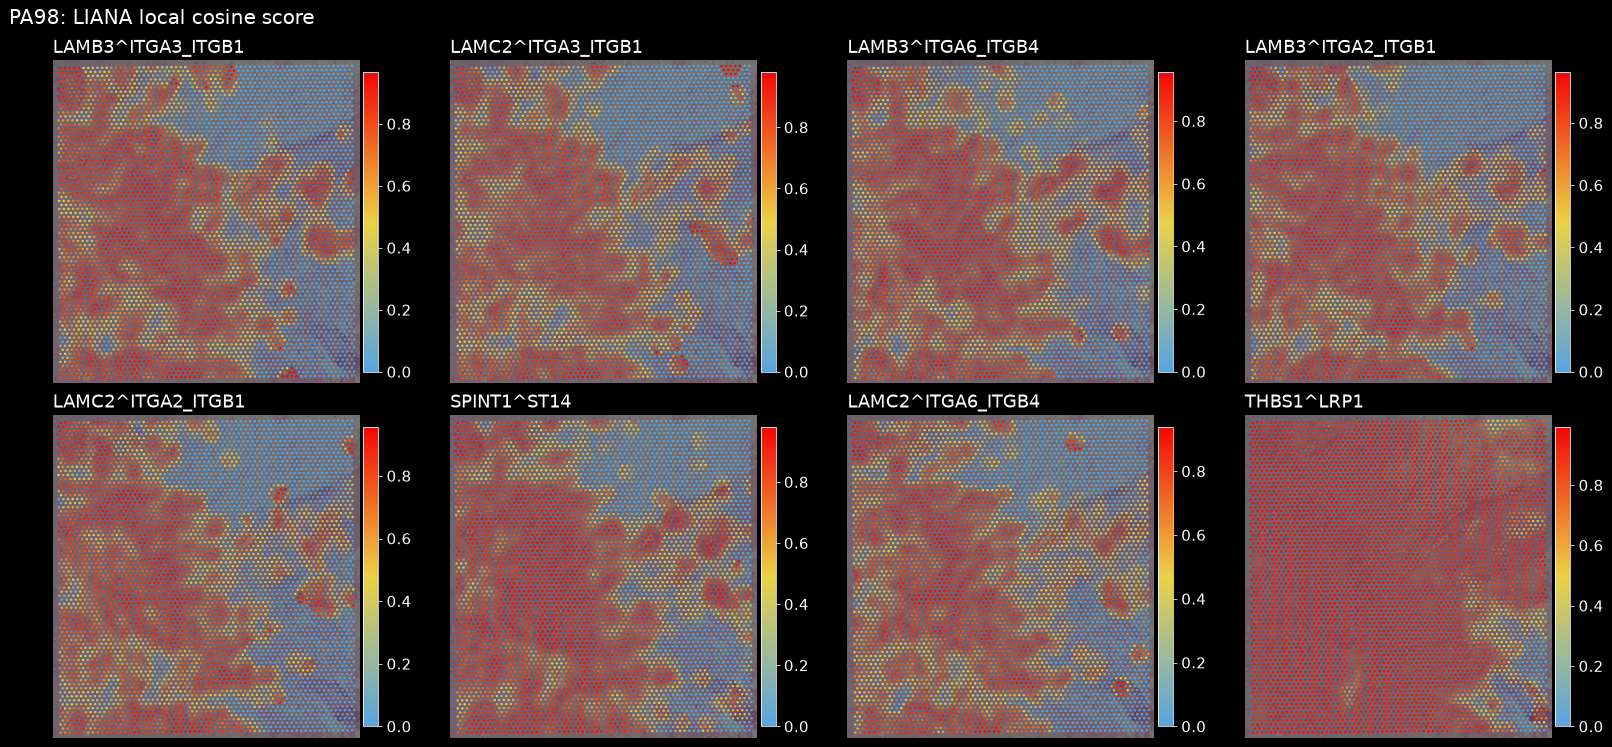

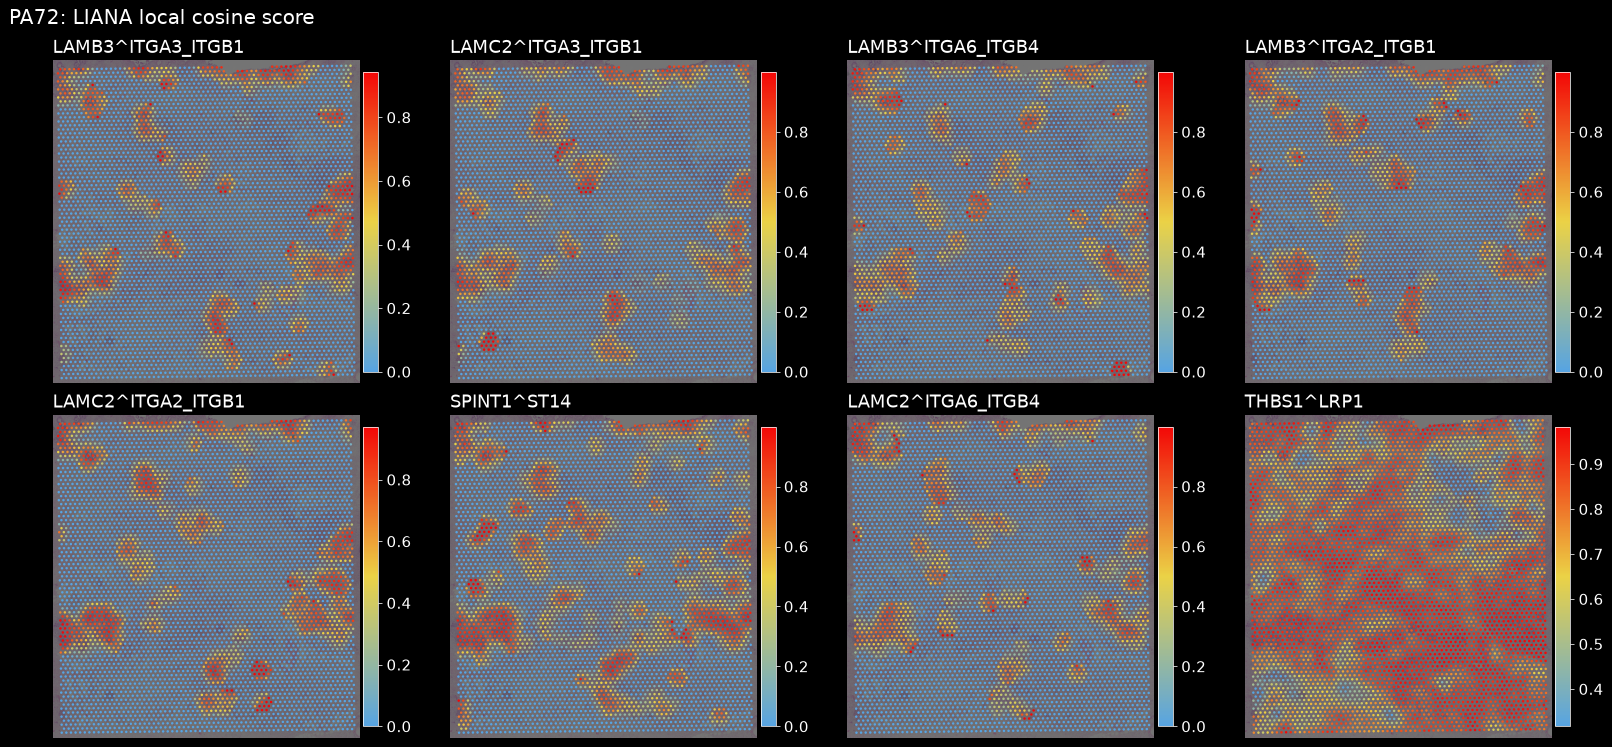

In [6]:
lr_show = scp._lr_display(df_lr_sig.index)[:8]
for lib in [scp.params['library_main'], 'PA72']:
    fig = scp.plot_lr_spatial(adata_lr, adata_expr, lr_show, library_id=lib, ncols=4, figsize=(18, 8), fontsize_title=14,
                              fontsize_suptitle=16, fontsize_colorbar=12, fname='fig_lr_top', force=force, verbose=verbose)
    plt.show()

### 4. LR pairs enriched in each region and subregion

**calc_df_lr_by_group**: per group, AUROC of the local score in vs out, mean score in / out, high-high fractions; **enriched** = AUROC >= **lr_group_min_auroc** and more high-high spots than elsewhere.

In [7]:
df_lr_region = scp.calc_df_lr_by_group(adata_lr, groups['region'], df_lr_sig.index, fname='lr_by_region', force=force, verbose=verbose)
df_lr_sub = scp.calc_df_lr_by_group(adata_lr, groups['subregion'], df_lr_sig.index, fname='lr_by_subregion', force=force, verbose=verbose)
df_n = pd.DataFrame({'n_enriched': df_lr_region[df_lr_region.enriched].groupby('group').size()}) \
         .reindex(sorted(groups['region'].dropna().unique())).fillna(0).astype(int)
df_n['region_name'] = df_n.index.map(region_name)
df_n['top_lr'] = scp.calc_df_lr_group_top(df_lr_region)
df_n

Out[7]: 
       n_enriched  ...                                                                                                                 top_lr
group              ...                                                                                                                       
R00           564  ...                 FGG^ITGB1 (0.86), LAMC3^CD44 (0.83), VTN^CD47 (0.82), VTN^ITGAV_ITGB8 (0.81), LAMC3^ITGA3_ITGB1 (0.81)
R01             0  ...                                                                                                                    NaN
R02           130  ...         FN1^ITGA8_ITGB1 (0.90), NTRK3^PTPRS (0.89), TNC^ITGA7 (0.88), TNC^ITGA8_ITGB1 (0.88), LAMB2^ITGA7_ITGB1 (0.87)
R03           305  ...                            CCL19^CCR7 (0.95), ST6GAL1^CD22 (0.90), CCL21^CCR7 (0.90), CD22^PTPRC (0.90), C3^CR1 (0.89)
R04           316  ...              LGI4^ADAM23 (0.91), COL9A3^CD44 (0.91), NRXN1^NLGN2 (0.91), NLGN2^NRXN1 (0.91), COL9A3^ITGAV_ITGB8 (0.9

,n_enriched,region_name,top_lr
group,,,
R00,564,N11_Non-malignant-pancreas,"FGG^ITGB1 (0.86), LAMC3^CD44 (0.83), VTN^CD47 (0.82), VTN^ITGAV_ITGB8 (0.81), LAMC3^ITGA3_ITGB1 (0.81)"
R01,0,N04_Plasma-enriched,NaN
R02,130,N03_Peri-vascular,"FN1^ITGA8_ITGB1 (0.90), NTRK3^PTPRS (0.89), TNC^ITGA7 (0.88), TNC^ITGA8_ITGB1 (0.88), LAMB2^ITGA7_ITGB1 (0.87)"
R03,305,N01_TLS,"CCL19^CCR7 (0.95), ST6GAL1^CD22 (0.90), CCL21^CCR7 (0.90), CD22^PTPRC (0.90), C3^CR1 (0.89)"
R04,316,N12_Nerve,"LGI4^ADAM23 (0.91), COL9A3^CD44 (0.91), NRXN1^NLGN2 (0.91), NLGN2^NRXN1 (0.91), COL9A3^ITGAV_ITGB8 (0.90)"
R05,3,N04_Plasma-enriched,"PECAM1^CD38 (0.81), PLA2G2A^ITGA5 (0.71), PLA2G2A^ITGA4 (0.68)"
R06,0,mixed (malignant / N05_CAF-enriched),NaN
R07,493,N05_CAF-enriched,"VCAN^TLR2 (0.84), BGN^TLR2 (0.83), DCN^TLR2 (0.83), CCN1^TLR2 (0.83), ANXA2^TLR2 (0.82)"
R08,67,N07-10_Malignant (Ductal-other),"ECM1^ITGB4 (0.73), LAMB3^ITGA3_ITGB1 (0.72), LAMC2^CD151 (0.71), LAMB3^CD151 (0.71), LAMC2^ITGA3_ITGB1 (0.71)"


In [8]:
fig = scp.plotly_lr_group_heatmap(df_lr_region, n_per_group=3, group_names=region_name, height=950, width=1800, fontsize_title=22,
                                  fontsize_xticks=13, fontsize_yticks=13, fontsize_colorbar=14, fontsize_hover=14,
                                  fname='fig_lr_region_hm', force=force, verbose=verbose)
fig.show()

### 5. LR pairs by nerve zone: invaded vs non-invaded (Figure 4F / 4G analogue)

Groups = nerve, juxta-neural (rings 1-2) and peri-neural (rings 3-5) spots of invaded and non-invaded nerves (mp_pdac03), each vs the rest of the tissue; CellChatDB resource (as the paper's COMMOT). The contrast **juxta-neural (non-invaded) vs (invaded)** is read from the two AUROC columns.

In [9]:
has_nerves = groups['nerve_zone'].replace('', np.nan).notna().any()
df_lr_nerve = scp.calc_df_lr_by_group(adata_lr_cc, groups['nerve_zone'], df_lr_sig_cc.index, fname='lr_by_nerve', force=force,
                                      verbose=verbose) if has_nerves else pd.DataFrame(columns=['group', 'interaction', 'auroc', 'enriched'])
print('nerve zones:', groups['nerve_zone'].value_counts().to_dict() if has_nerves else 'none (no nerve called in mp_pdac03)')
P = df_lr_nerve.pivot_table(index='interaction', columns='group', values='auroc') if len(df_lr_nerve) else pd.DataFrame()
if {'juxta-neural (non-invaded)', 'juxta-neural (invaded)'} <= set(P.columns):
    P['delta_juxta_non_minus_inv'] = P['juxta-neural (non-invaded)'] - P['juxta-neural (invaded)']
    keep = scp._lr_display(P.index)
    display(P.loc[keep].sort_values('delta_juxta_non_minus_inv', ascending=False).head(15).round(3))
    display(P.loc[keep].sort_values('delta_juxta_non_minus_inv').head(15).round(3))

nerve zones: {'peri-neural (non-invaded)': 3543, 'juxta-neural (non-invaded)': 1810, 'peri-neural (invaded)': 1017, 'nerve (non-invaded)': 870, 'juxta-neural (invaded)': 455, 'nerve (invaded)': 103}


group,juxta-neural (invaded),juxta-neural (non-invaded),nerve (invaded),nerve (non-invaded),peri-neural (invaded),peri-neural (non-invaded),delta_juxta_non_minus_inv
interaction,,,,,,,
FGF7^FGFR1,0.236,0.597,0.246,0.549,0.262,0.591,0.361
FGF10^FGFR1,0.228,0.584,0.214,0.620,0.324,0.548,0.355
SELE^CD44,0.275,0.622,0.254,0.653,0.285,0.512,0.347
COL4A4^CD44,0.285,0.612,0.235,0.494,0.310,0.570,0.327
CCL5^ACKR1,0.278,0.597,0.276,0.509,0.294,0.582,0.319
CCL14^ACKR1,0.281,0.598,0.272,0.562,0.312,0.551,0.317
CCL2^ACKR1,0.296,0.612,0.305,0.642,0.274,0.522,0.316
FGF2^FGFR1,0.294,0.592,0.258,0.785,0.267,0.485,0.298
CXCL12^CXCR4,0.265,0.562,0.191,0.550,0.309,0.591,0.297


group,juxta-neural (invaded),juxta-neural (non-invaded),nerve (invaded),nerve (non-invaded),peri-neural (invaded),peri-neural (non-invaded),delta_juxta_non_minus_inv
interaction,,,,,,,
LAMB3^ITGA3_ITGB1,0.792,0.419,0.783,0.481,0.766,0.365,-0.373
LAMA3^ITGA3_ITGB1,0.761,0.408,0.753,0.488,0.747,0.387,-0.354
LAMC2^ITGA3_ITGB1,0.767,0.426,0.765,0.460,0.766,0.374,-0.341
LAMB3^ITGA6_ITGB1,0.773,0.438,0.744,0.479,0.718,0.380,-0.335
FN1^ITGA3_ITGB1,0.754,0.429,0.766,0.591,0.718,0.345,-0.325
LAMB3^ITGA6_ITGB4,0.762,0.437,0.742,0.494,0.732,0.371,-0.325
LAMC2^ITGA6_ITGB1,0.748,0.434,0.740,0.476,0.734,0.382,-0.314
LAMC2^ITGA6_ITGB4,0.752,0.440,0.739,0.494,0.743,0.366,-0.312
LAMB3^DAG1,0.744,0.440,0.748,0.461,0.676,0.411,-0.304


In [10]:
if len(df_lr_nerve):
    fig = scp.plotly_lr_group_heatmap(df_lr_nerve, n_per_group=5, height=900, width=1700, fontsize_title=22, fontsize_xticks=13,
                                      fontsize_yticks=13, fontsize_colorbar=14, fontsize_hover=14, fname='fig_lr_nerve_hm', force=force,
                                      verbose=verbose)
    fig.show()

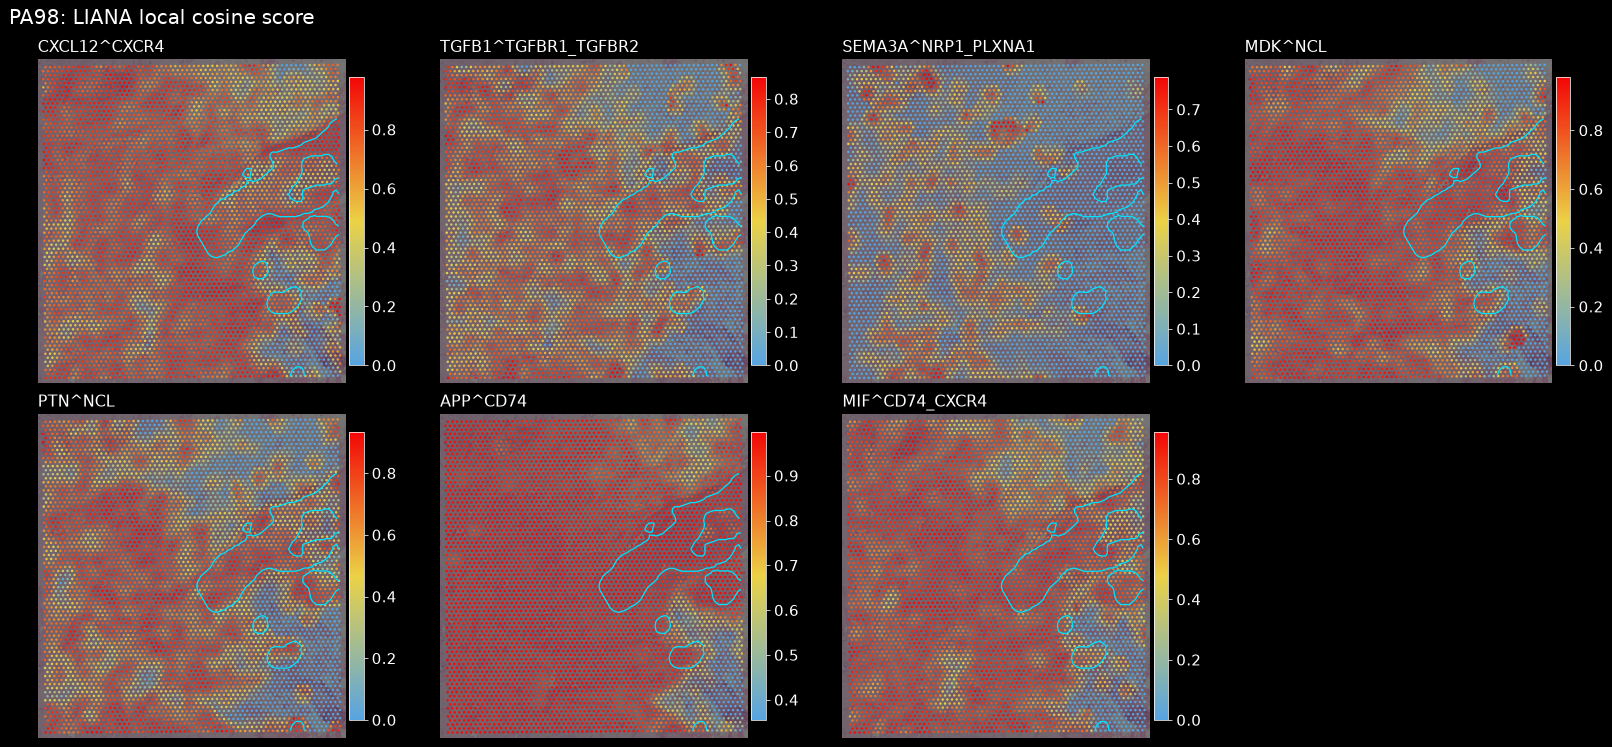

In [11]:
top_nerve = [i for i in ['CXCL12^CXCR4', 'TGFB1^TGFBR1_TGFBR2', 'SEMA3A^NRP1_PLXNA1', 'MDK^NCL', 'PTN^NCL', 'APP^CD74', 'MIF^CD74_CXCR4']
             if i in adata_lr_cc.var_names]
lib = scp.params['library_main']
reg = adata_expr.obs['nerve_zone_status'].astype(str).values
fig = scp.plot_lr_spatial(adata_lr_cc, adata_expr, top_nerve or scp._lr_display(df_lr_sig_cc.index)[:6], library_id=lib, ncols=4,
                          figsize=(18, 8), outlines=[np.char.startswith(reg.astype(str), 'nerve')] * max(1, len(top_nerve)),
                          fontsize_title=13, fontsize_suptitle=16, fontsize_colorbar=12, fname='fig_lr_nerve', force=force, verbose=verbose)
plt.show()

### 6. LR pairs by NI group

Low vs high NI sections as groups (AUROC of the local score in the group's spots vs the other group). The ranking is repeated on the CytAssist sections only (all low-NI sections are CytAssist).

In [12]:
df_lr_ni = scp.calc_df_lr_by_group(adata_lr, groups['ni_status'], df_lr_sig.index, fname='lr_by_ni', force=force, verbose=verbose)
cyt = (adata_expr.obs.technique.astype(str) == 'CytAssist').values
g_cyt = groups['ni_status'].where(cyt)
df_lr_ni_cyt = scp.calc_df_lr_by_group(adata_lr[cyt], g_cyt[cyt], df_lr_sig.index, fname=None, force=True, verbose=verbose)
keep = set(scp._lr_display(df_lr_ni.interaction.unique()))
M = pd.concat({'all': df_lr_ni.pivot_table(index='interaction', columns='group', values='auroc'),
               'CytAssist': df_lr_ni_cyt.pivot_table(index='interaction', columns='group', values='auroc')}, axis=1)
M = M.loc[[i for i in M.index if i in keep]]
display(M.sort_values(('CytAssist', 'low'), ascending=False).head(15).round(3))
display(M.sort_values(('CytAssist', 'high'), ascending=False).head(15).round(3))

all        CytAssist       
group           high    low      high    low
interaction                                 
PLA2G2A^ITGA5  0.337  0.663     0.422  0.579
PLA2G2A^ITGA4  0.352  0.649     0.428  0.572
ADCYAP1^ADRB2  0.405  0.595     0.448  0.552
VEGFC^LYVE1    0.390  0.611     0.452  0.548
GCG^ADRB2      0.424  0.577     0.454  0.546
GCG^GPR20      0.416  0.583     0.453  0.546
SST^SSTR2      0.455  0.545     0.455  0.545
ADCYAP1^VIPR2  0.431  0.569     0.456  0.544
TTR^NGFR       0.451  0.549     0.460  0.540
VWF^SCARA5     0.412  0.588     0.461  0.539
CCL5^ACKR1     0.413  0.587     0.461  0.539
CCL14^ACKR1    0.438  0.562     0.467  0.533
ADCYAP1^GPR20  0.432  0.568     0.467  0.532
CCL8^ACKR1     0.446  0.554     0.471  0.529
ADCYAP1^PTH1R  0.454  0.546     0.473  0.528

all        CytAssist       
group                 high    low      high    low
interaction                                       
COL3A1^ITGA2_ITGB1   0.822  0.178     0.876  0.124
COL1A1^ITGA2_ITGB1   0.822  0.178     0.876  0.124
COL1A2^ITGA2_ITGB1   0.823  0.178     0.875  0.125
LAMB3^CD151          0.868  0.132     0.875  0.125
COL6A3^ITGA2_ITGB1   0.807  0.193     0.873  0.128
COL5A1^ITGA2_ITGB1   0.812  0.188     0.871  0.129
LAMB3^CD44           0.844  0.156     0.871  0.129
FN1^ITGA2            0.816  0.184     0.870  0.130
COL4A1^ITGA2_ITGB1   0.811  0.189     0.868  0.132
COL4A2^ITGA2_ITGB1   0.807  0.193     0.866  0.134
COL5A2^ITGA2_ITGB1   0.808  0.192     0.865  0.135
FN1^ITGAV_ITGB6      0.815  0.185     0.863  0.137
LAMC2^CD151          0.850  0.150     0.862  0.138
SLPI^PLSCR1          0.813  0.187     0.861  0.139
COL18A1^ITGA2_ITGB1  0.807  0.193     0.860  0.140

### 7. Between cell types: sender -> receiver

**calc_celltype_expr** splits each spot's counts across cell types (abundance x signature); **calc_df_celltype_lr** for the **lr_top_n** significant pairs (consensus) plus the CellChatDB pairs of section 8: score[A, B] = mean over spots of (W_norm L_A) x R_B, receptor spots permuted -> z; per group (regions, nerve zones, NI groups).

In [13]:
extra = [i for i in df_lr_sig_cc.index if any(k in i for k in ('TGFB', 'HGF', 'CXCL12', 'SEMA3', 'NGF', 'GDNF', 'NRTN', 'ARTN', 'BDNF'))]
df_lr_top = pd.concat([df_lr_sig.head(scp.params['lr_top_n'])[['ligand', 'receptor']],
                       df_lr_sig_cc.loc[extra, ['ligand', 'receptor']]])
df_lr_top = df_lr_top[~df_lr_top.index.duplicated()]
genes = sorted({s for e in list(df_lr_top.ligand) + list(df_lr_top.receptor) for s in e.split('_')})
E, genes_E, celltypes_E = scp.calc_celltype_expr(adata_expr, df_abund.loc[adata_expr.obs_names, celltypes], df_sig[celltypes], genes)
print('E (spots x cell types x genes):', E.shape)
groups_ct = {'region': groups['region'], 'nerve_zone': groups['nerve_zone'], 'ni_status': groups['ni_status']}
df_ct, df_group_ct = scp.calc_df_celltype_lr(E, genes_E, celltypes_E, df_lr_top, W, groups=groups_ct, force=force, verbose=verbose)
df_best = df_ct[df_ct.rank_in_lr == 1].set_index('interaction')
df_best[['sender', 'receiver', 'score', 'score_share', 'z']].head(20).round(3)

E (spots x cell types x genes): (81846, 42, 125)
Out[13]: 
                                      sender  ...        z
interaction                                   ...         
A2M^LRP1                     F01_myCAF-MMP11  ...  202.706
ADAM9^ITGA3                 D04_Ductal-GABRP  ...  236.120
ADAM9^ITGB1                 D04_Ductal-GABRP  ...  248.565
AGRN^ITGB1                  D04_Ductal-GABRP  ...  223.950
APOE^LRP1                    M08_Macro-LYVE1  ...   81.606
APOE^TREM2                   M09_Macro-APOC1  ...  159.448
APP^LRP10                    F01_myCAF-MMP11  ...  202.425
APP^TNFRSF21                D04_Ductal-GABRP  ...  210.831
C1QB^LRP1                    M08_Macro-LYVE1  ...  129.175
C3^LRP1               F02_Progenitor-CAF-DPT  ...  222.903
CCL14^ACKR1                      Endothelial  ...  119.316
CCL19^CCR7            F02_Progenitor-CAF-DPT  ...   80.213
CCN2^LRP1                    F01_myCAF-MMP11  ...  213.944
CD14^ITGB2                   M08_Macro-LYVE1  ...  133.8

,sender,receiver,score,score_share,z
interaction,,,,,
A2M^LRP1,F01_myCAF-MMP11,F01_myCAF-MMP11,0.810,0.105,202.706
ADAM9^ITGA3,D04_Ductal-GABRP,D04_Ductal-GABRP,0.169,0.120,236.120
ADAM9^ITGB1,D04_Ductal-GABRP,D04_Ductal-GABRP,0.173,0.052,248.565
AGRN^ITGB1,D04_Ductal-GABRP,D04_Ductal-GABRP,0.267,0.066,223.950
APOE^LRP1,M08_Macro-LYVE1,F02_Progenitor-CAF-DPT,0.522,0.058,81.606
APOE^TREM2,M09_Macro-APOC1,M09_Macro-APOC1,0.151,0.082,159.448
APP^LRP10,F01_myCAF-MMP11,F01_myCAF-MMP11,0.358,0.060,202.425
APP^TNFRSF21,D04_Ductal-GABRP,D04_Ductal-GABRP,0.173,0.043,210.831
C1QB^LRP1,M08_Macro-LYVE1,F02_Progenitor-CAF-DPT,0.405,0.132,129.175


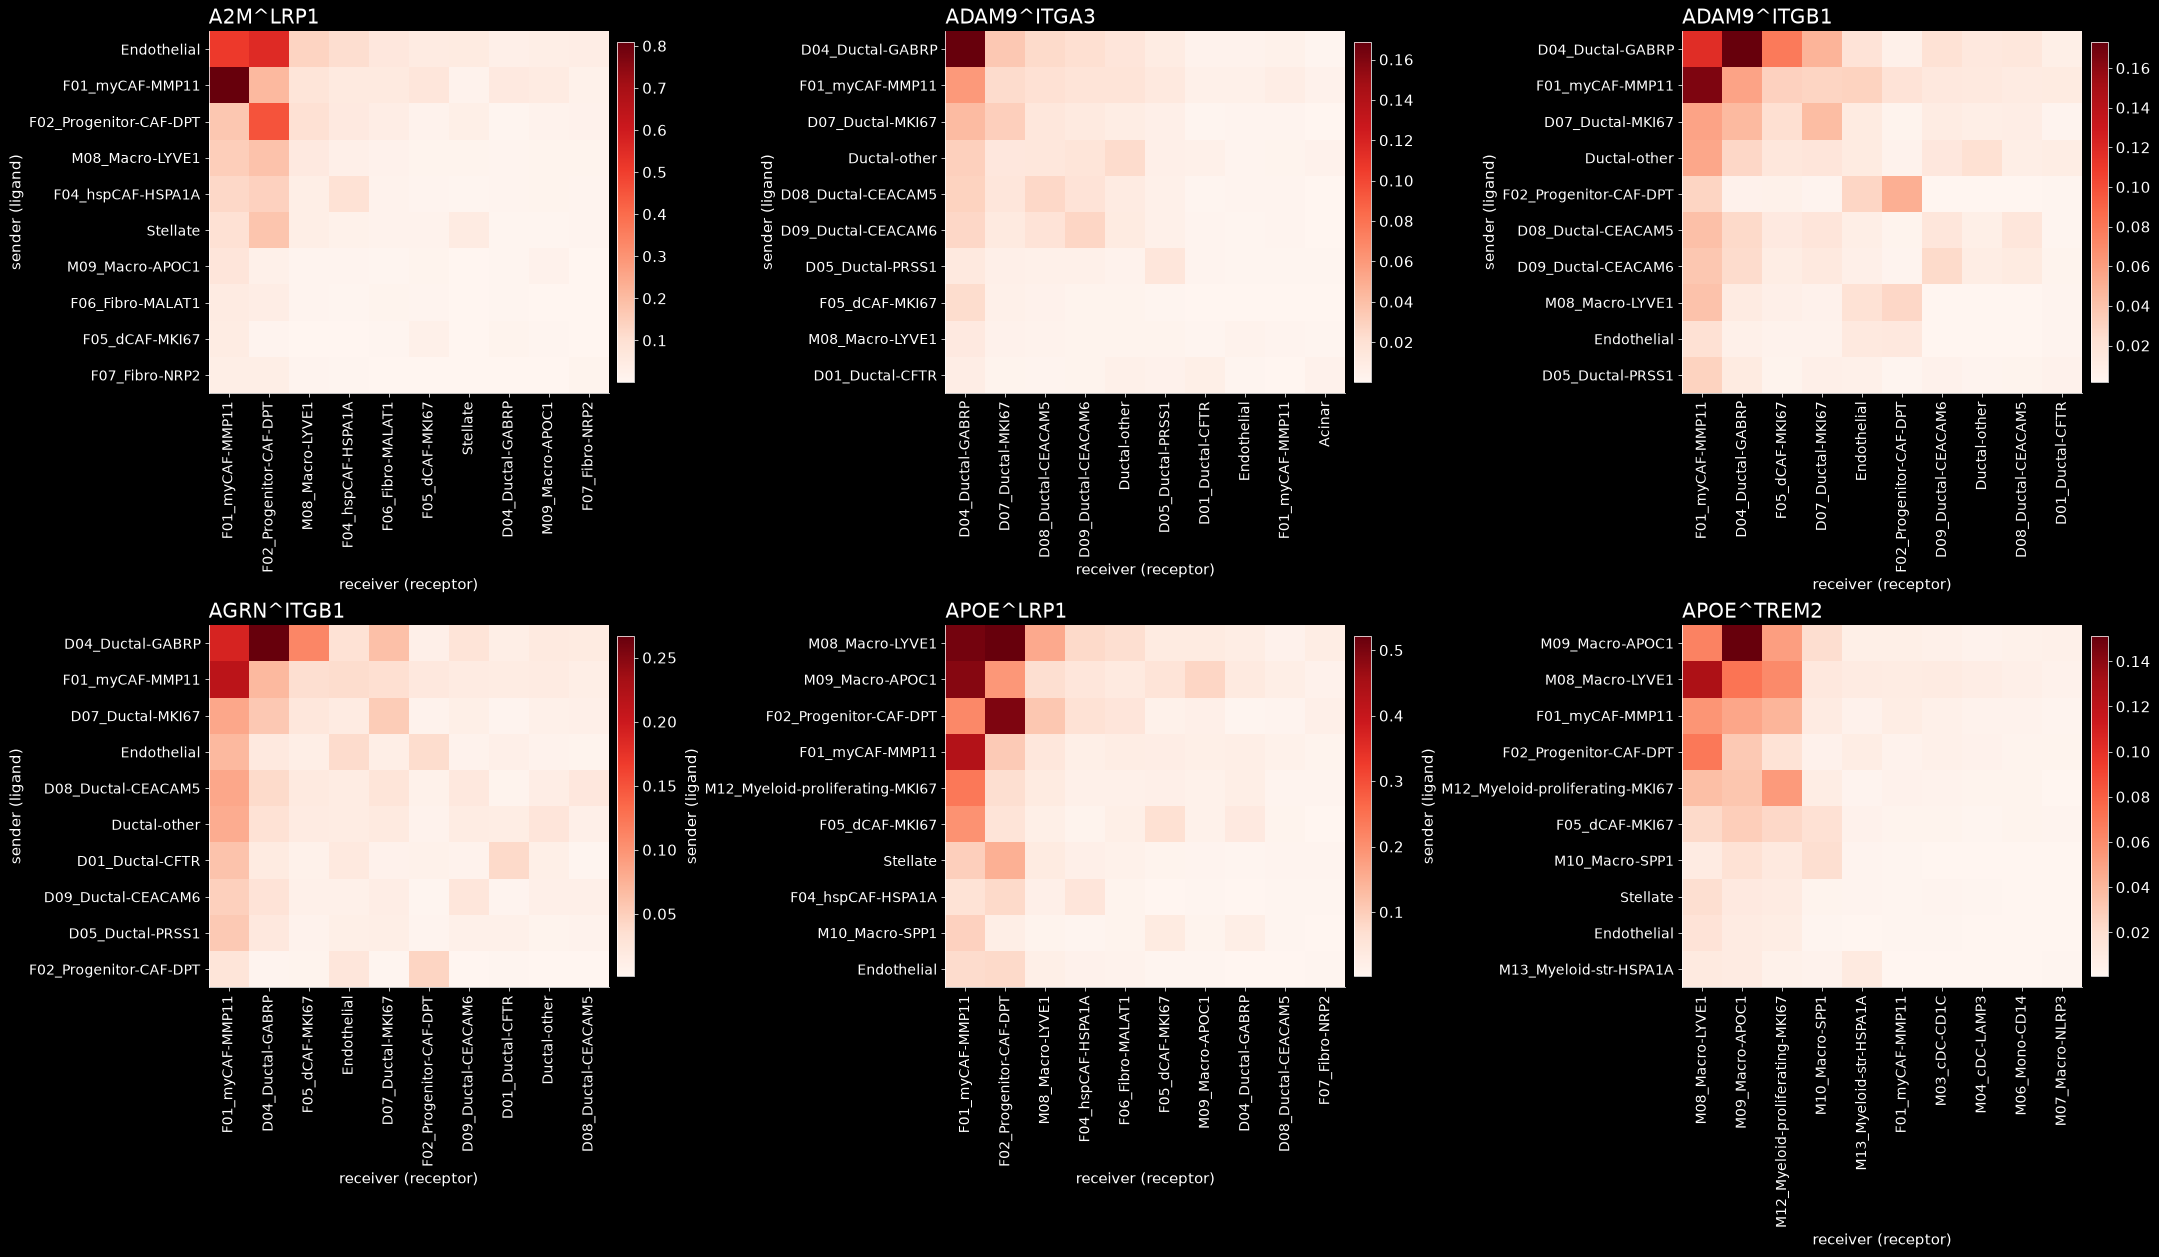

In [14]:
lr_panels = scp._lr_display(df_best.index)[:6]
fig = scp.plot_sender_receiver_heatmaps(df_ct, lr_panels, n_top=10, ncols=3, panel_size=(8, 7.0), fontsize_title=16, fontsize_ticks=11,
                                        fontsize_label=12, fontsize_colorbar=12, fname='fig_sender_recv', force=force, verbose=verbose)
plt.show()

In [15]:
df_links = scp.calc_df_group_celltype_links(df_group_ct, force=force, verbose=verbose)
lev = df_group_ct.drop_duplicates('group').set_index('group').level
df_links_nerve = df_links[df_links.group.map(lev) == 'nerve_zone']
fig = scp.plotly_group_celltype_links(df_links_nerve, n_links=30, groups=sorted(df_links_nerve.group.unique()), height=1000, width=1600,
                                      fontsize_title=22, fontsize_xticks=13, fontsize_yticks=13, fontsize_colorbar=14, fontsize_hover=14,
                                      fname='fig_links_nerve', force=force, verbose=verbose)
fig.show()
df_links_nerve[~df_links_nerve.self_link].groupby('group').head(4)[['group', 'link', 'n_lr', 'lr']]

Out[15]: 
                           group  ...                                                                                                               lr
1545      juxta-neural (invaded)  ...                                FN1^ITGA3_ITGB1, LGALS1^ITGB1, FN1^PLAUR, FN1^ITGA2, TIMP2^ITGB1, FN1^ITGAV_ITGB1
1546      juxta-neural (invaded)  ...                           LGALS1^ITGB1, FN1^ITGA5_ITGB1, VCAN^ITGB1, TIMP2^ITGB1, COL1A2^ITGA1_ITGB1, PLAU^ITGB1
1547      juxta-neural (invaded)  ...                            FN1^ITGA3_ITGB1, FN1^ITGA2, FN1^PLAUR, LGALS1^ITGB1, FN1^ITGAV_ITGB1, FN1^ITGA5_ITGB1
1548      juxta-neural (invaded)  ...               FN1^ITGAV_ITGB1, LGALS1^ITGB1, COL1A2^ITGA1_ITGB1, FN1^PLAUR, FN1^ITGA5_ITGB1, COL1A1^ITGA11_ITGB1
1609  juxta-neural (non-invaded)  ...                                    SPARC^ENG, TIMP1^CD63, VCAN^ITGB1, TIMP2^ITGB1, LGALS1^ITGB1, FN1^ITGA5_ITGB1
1610  juxta-neural (non-invaded)  ...                           PSAP^LRP1, FN1^ITGAV

,group,link,n_lr,lr
1545,juxta-neural (invaded),F01_myCAF-MMP11 -> D04_Ductal-GABRP,25,"FN1^ITGA3_ITGB1, LGALS1^ITGB1, FN1^PLAUR, FN1^ITGA2, TIMP2^ITGB1, FN1^ITGAV_ITGB1"
1546,juxta-neural (invaded),F01_myCAF-MMP11 -> F05_dCAF-MKI67,22,"LGALS1^ITGB1, FN1^ITGA5_ITGB1, VCAN^ITGB1, TIMP2^ITGB1, COL1A2^ITGA1_ITGB1, PLAU^ITGB1"
1547,juxta-neural (invaded),F05_dCAF-MKI67 -> D04_Ductal-GABRP,21,"FN1^ITGA3_ITGB1, FN1^ITGA2, FN1^PLAUR, LGALS1^ITGB1, FN1^ITGAV_ITGB1, FN1^ITGA5_ITGB1"
1548,juxta-neural (invaded),F05_dCAF-MKI67 -> F01_myCAF-MMP11,20,"FN1^ITGAV_ITGB1, LGALS1^ITGB1, COL1A2^ITGA1_ITGB1, FN1^PLAUR, FN1^ITGA5_ITGB1, COL1A1^ITGA11_ITGB1"
1609,juxta-neural (non-invaded),F02_Progenitor-CAF-DPT -> Endothelial,27,"SPARC^ENG, TIMP1^CD63, VCAN^ITGB1, TIMP2^ITGB1, LGALS1^ITGB1, FN1^ITGA5_ITGB1"
1610,juxta-neural (non-invaded),S02_Schwann-TGFBI -> F01_myCAF-MMP11,26,"PSAP^LRP1, FN1^ITGAV_ITGB1, TIMP2^ITGB1, LGALS1^ITGB1, LGALS3BP^ITGB1, FN1^ITGA5_ITGB1"
1612,juxta-neural (non-invaded),Endothelial -> F02_Progenitor-CAF-DPT,23,"A2M^LRP1, SPARC^ENG, HSPG2^LRP1, PSAP^LRP1, THBS1^LRP1, CCN2^LRP1"
1613,juxta-neural (non-invaded),F02_Progenitor-CAF-DPT -> M08_Macro-LYVE1,14,"C3^LRP1, TIMP1^CD63, THBS1^LRP1, CXCL12^CXCR4, SERPINF1^PLXDC2, CCN2^LRP1"
1765,nerve (invaded),D04_Ductal-GABRP -> F01_myCAF-MMP11,30,"TGM2^ITGB1, LGALS3BP^ITGB1, TIMP2^ITGB1, MMP7^SDC1, AGRN^ITGB1, PLAU^ITGB1"
1766,nerve (invaded),F01_myCAF-MMP11 -> D04_Ductal-GABRP,28,"FN1^ITGA3_ITGB1, LGALS1^ITGB1, FN1^PLAUR, TIMP1^CD63, TIMP2^ITGB1, VCAN^ITGB1"


### 8. TGF-beta and HGF towards S02_Schwann-TGFBI; CXCL12 -> CXCR4 around non-invaded nerves

Paper (Figure 6): TGFB1 from M07_Macro-NLRP3, myCAF and malignant cells induces TGFBI+ Schwann cells (CellChat TGF-beta network; NicheNet ligands TGFB1, HGF). Here: sender -> receiver scores of the TGF-beta / HGF pairs with **S02_Schwann-TGFBI** (and S01 / S03 for comparison) as receivers, whole tissue and per nerve zone. Paper (Figure 4H): CXCL12 from LUM+ fibroblasts and CXCR4+ B cells around non-invaded nerves.

Out[16]: 
                  interaction ligand  ... score_share rank_in_lr
0         TGFB3^TGFBR1_TGFBR2  TGFB3  ...    0.005074         35
1         TGFB3^TGFBR1_TGFBR2  TGFB3  ...    0.003411         51
2         TGFB3^TGFBR1_TGFBR2  TGFB3  ...    0.001903         87
3   TGFB3^ACVR1_TGFBR1_TGFBR2  TGFB3  ...    0.004684         41
4         TGFB3^TGFBR1_TGFBR2  TGFB3  ...    0.001428        103
5   TGFB3^ACVR1_TGFBR1_TGFBR2  TGFB3  ...    0.004193         44
6         TGFB1^TGFBR1_TGFBR2  TGFB1  ...    0.001658        123
7         TGFB3^TGFBR1_TGFBR2  TGFB3  ...    0.001232        115
8         TGFB2^TGFBR1_TGFBR2  TGFB2  ...    0.002616         72
9         TGFB1^TGFBR1_TGFBR2  TGFB1  ...    0.001234        155
10        TGFB1^TGFBR1_TGFBR2  TGFB1  ...    0.001090        172
11        TGFB3^TGFBR1_TGFBR2  TGFB3  ...    0.000860        156
12  TGFB3^ACVR1_TGFBR1_TGFBR2  TGFB3  ...    0.002495         63
13        TGFB3^ACVR1B_TGFBR2  TGFB3  ...    0.001656         99
14        TGFB1

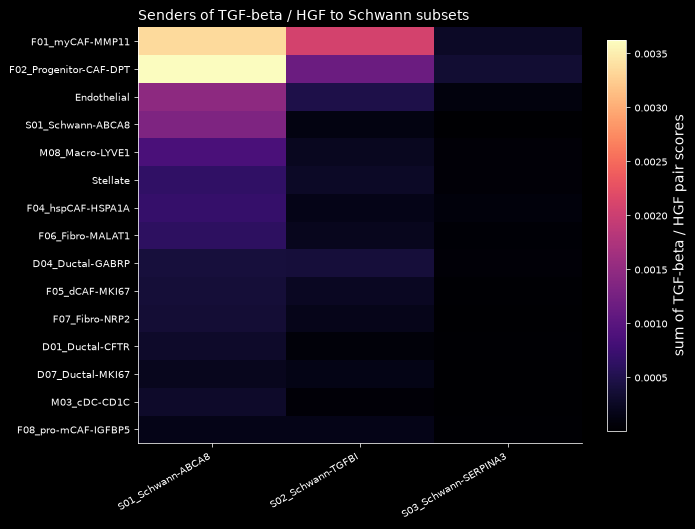

,interaction,ligand,receptor,sender,receiver,score,z,p_emp,p,fdr,score_share,rank_in_lr
0,TGFB3^TGFBR1_TGFBR2,TGFB3,TGFBR1_TGFBR2,F02_Progenitor-CAF-DPT,S01_Schwann-ABCA8,0.002079,13.637777,0.004975,1.000000e-12,4.502247e-12,0.005074,35
1,TGFB3^TGFBR1_TGFBR2,TGFB3,TGFBR1_TGFBR2,F01_myCAF-MMP11,S01_Schwann-ABCA8,0.001397,-12.967946,1.000000,1.000000e+00,1.000000e+00,0.003411,51
2,TGFB3^TGFBR1_TGFBR2,TGFB3,TGFBR1_TGFBR2,F01_myCAF-MMP11,S02_Schwann-TGFBI,0.000780,10.683051,0.004975,1.000000e-12,4.502247e-12,0.001903,87
3,TGFB3^ACVR1_TGFBR1_TGFBR2,TGFB3,ACVR1_TGFBR1_TGFBR2,F02_Progenitor-CAF-DPT,S01_Schwann-ABCA8,0.000619,4.735511,0.004975,1.092518e-06,4.116613e-06,0.004684,41
4,TGFB3^TGFBR1_TGFBR2,TGFB3,TGFBR1_TGFBR2,F02_Progenitor-CAF-DPT,S02_Schwann-TGFBI,0.000585,10.475970,0.004975,1.000000e-12,4.502247e-12,0.001428,103
5,TGFB3^ACVR1_TGFBR1_TGFBR2,TGFB3,ACVR1_TGFBR1_TGFBR2,F01_myCAF-MMP11,S01_Schwann-ABCA8,0.000555,-5.789069,1.000000,1.000000e+00,1.000000e+00,0.004193,44
6,TGFB1^TGFBR1_TGFBR2,TGFB1,TGFBR1_TGFBR2,F01_myCAF-MMP11,S01_Schwann-ABCA8,0.000549,-25.624848,1.000000,1.000000e+00,1.000000e+00,0.001658,123
7,TGFB3^TGFBR1_TGFBR2,TGFB3,TGFBR1_TGFBR2,Endothelial,S01_Schwann-ABCA8,0.000505,19.257569,0.004975,1.000000e-12,4.502247e-12,0.001232,115
8,TGFB2^TGFBR1_TGFBR2,TGFB2,TGFBR1_TGFBR2,S01_Schwann-ABCA8,S01_Schwann-ABCA8,0.000459,105.012296,0.004975,1.000000e-12,4.502247e-12,0.002616,72
9,TGFB1^TGFBR1_TGFBR2,TGFB1,TGFBR1_TGFBR2,Endothelial,S01_Schwann-ABCA8,0.000409,0.098026,0.447761,4.477612e-01,1.000000e+00,0.001234,155


In [16]:
df_tgfb = scp.calc_df_tgfb_to_schwann(df_ct, top=5, fname='tsv_tgfb', force=force, verbose=verbose)
fig = scp.plot_tgfb_to_schwann(df_ct, n_senders=15, fname='fig_tgfb', force=force, verbose=verbose)
plt.show()
df_tgfb.head(20)

In [17]:
cx = [i for i in df_group_ct.interaction.unique() if i.startswith('CXCL12^')]
d_c = df_group_ct[df_group_ct.interaction.isin(cx) & (df_group_ct.level == 'nerve_zone')]
d_c.sort_values('score', ascending=False).groupby('group').head(3)[['group', 'interaction', 'sender', 'receiver', 'score', 'z', 'ratio']].round(3) if len(d_c) else 'no CXCL12 pair scored'

Out[17]: 
                            group   interaction  ...       z   ratio
34270   peri-neural (non-invaded)  CXCL12^CXCR4  ...   8.966   1.690
34260  juxta-neural (non-invaded)  CXCL12^CXCR4  ...   3.592   1.686
34271   peri-neural (non-invaded)  CXCL12^CXCR4  ...   5.763   2.739
34272   peri-neural (non-invaded)  CXCL12^CXCR4  ...   7.915   2.280
34280         nerve (non-invaded)  CXCL12^CXCR4  ...  -4.883   1.321
34261  juxta-neural (non-invaded)  CXCL12^CXCR4  ...   3.769   2.556
34262  juxta-neural (non-invaded)  CXCL12^CXCR4  ...   4.860   1.997
37340         nerve (non-invaded)  CXCL12^ACKR3  ...  -5.347  12.009
34281         nerve (non-invaded)  CXCL12^CXCR4  ...  -6.379   2.334
34290       peri-neural (invaded)  CXCL12^CXCR4  ...  14.266   0.838
34291       peri-neural (invaded)  CXCL12^CXCR4  ...  11.439   0.300
34292       peri-neural (invaded)  CXCL12^CXCR4  ...  13.477   1.835
37370             nerve (invaded)  CXCL12^ACKR3  ...   0.286  18.000
34300      juxta-neural 

,group,interaction,sender,receiver,score,z,ratio
34270,peri-neural (non-invaded),CXCL12^CXCR4,F02_Progenitor-CAF-DPT,M08_Macro-LYVE1,0.269,8.966,1.690
34260,juxta-neural (non-invaded),CXCL12^CXCR4,F02_Progenitor-CAF-DPT,M08_Macro-LYVE1,0.269,3.592,1.686
34271,peri-neural (non-invaded),CXCL12^CXCR4,F02_Progenitor-CAF-DPT,B,0.225,5.763,2.739
34272,peri-neural (non-invaded),CXCL12^CXCR4,F02_Progenitor-CAF-DPT,CD4T,0.216,7.915,2.280
34280,nerve (non-invaded),CXCL12^CXCR4,F02_Progenitor-CAF-DPT,M08_Macro-LYVE1,0.211,-4.883,1.321
34261,juxta-neural (non-invaded),CXCL12^CXCR4,F02_Progenitor-CAF-DPT,B,0.210,3.769,2.556
34262,juxta-neural (non-invaded),CXCL12^CXCR4,F02_Progenitor-CAF-DPT,CD4T,0.189,4.860,1.997
37340,nerve (non-invaded),CXCL12^ACKR3,F02_Progenitor-CAF-DPT,S01_Schwann-ABCA8,0.115,-5.347,12.009
34281,nerve (non-invaded),CXCL12^CXCR4,F02_Progenitor-CAF-DPT,M03_cDC-CD1C,0.114,-6.379,2.334
34290,peri-neural (invaded),CXCL12^CXCR4,F01_myCAF-MMP11,M08_Macro-LYVE1,0.052,14.266,0.838


### 9. Reference LIANA (rank_aggregate) + cell-type co-localisation

**liana_rank_aggregate_reference** on the reference (<= **ref_lr_cells_per_type** cells per type); non-spatial, so each source -> target is annotated with the co-localisation of the two cell types (**calc_df_celltype_coloc**).

In [18]:
adata_ref_sym = adata_ref_dec.copy()
df_liref = scp.liana_rank_aggregate_reference(adata_ref_sym, 'cell_type', symbol_col='symbol', force=force, verbose=verbose)
df_coloc, coloc_region = scp.calc_df_celltype_coloc(df_abund.loc[adata_expr.obs_names, celltypes_E], W, groups['region'])
df_ref_sup = scp.calc_df_ref_lr_support(df_liref, df_coloc, coloc_region, force=force, verbose=verbose)
print(f"reference interactions: {len(df_liref)}; specific & strong: {len(df_ref_sup)}; spatially supported: {int(df_ref_sup.spatially_supported.sum())}")
df_ref_sup[df_ref_sup.spatially_supported & df_ref_sup.listed][['source', 'target', 'interaction', 'magnitude_rank', 'specificity_rank',
                                                                'coloc', 'best_group', 'coloc_group']].head(20).round(3)

reference interactions: 460325; specific & strong: 33391; spatially supported: 9436
Out[18]: 
                    source                  target  ... best_group  coloc_group
0              Endothelial          M02_cDC-CLEC9A  ...        R03        2.005
1            Myeloid-other          M02_cDC-CLEC9A  ...        R03        1.888
2         D02_Ductal-APOA2          M02_cDC-CLEC9A  ...        R06        2.033
3              Endothelial           Myeloid-other  ...        R06        2.809
4           F05_dCAF-MKI67         M07_Macro-NLRP3  ...        R25        1.746
5   F02_Progenitor-CAF-DPT            M14_Mast-KIT  ...        R13        1.675
9                   Acinar           M06_Mono-CD14  ...        R24        1.348
10         F01_myCAF-MMP11         M07_Macro-NLRP3  ...        R16        1.430
11  F02_Progenitor-CAF-DPT            M14_Mast-KIT  ...        R13        1.675
12          F05_dCAF-MKI67          M10_Macro-SPP1  ...        R22        4.749
13  F02_Progenitor-CAF-DPT

,source,target,interaction,magnitude_rank,specificity_rank,coloc,best_group,coloc_group
0,Endothelial,M02_cDC-CLEC9A,APP^CD74,0.0,0.030,0.298,R03,2.005
1,Myeloid-other,M02_cDC-CLEC9A,APP^CD74,0.0,0.034,0.237,R03,1.888
2,D02_Ductal-APOA2,M02_cDC-CLEC9A,APP^CD74,0.0,0.045,0.104,R06,2.033
3,Endothelial,Myeloid-other,APP^CD74,0.0,0.048,0.195,R06,2.809
4,F05_dCAF-MKI67,M07_Macro-NLRP3,FN1^PLAUR,0.0,0.001,0.093,R25,1.746
5,F02_Progenitor-CAF-DPT,M14_Mast-KIT,COL1A1^CD44,0.0,0.004,0.361,R13,1.675
9,Acinar,M06_Mono-CD14,CEL^CXCR4,0.0,0.000,-0.040,R24,1.348
10,F01_myCAF-MMP11,M07_Macro-NLRP3,COL1A1^CD44,0.0,0.008,-0.048,R16,1.430
11,F02_Progenitor-CAF-DPT,M14_Mast-KIT,COL1A2^CD44,0.0,0.004,0.361,R13,1.675
12,F05_dCAF-MKI67,M10_Macro-SPP1,FN1^PLAUR,0.0,0.001,0.539,R22,4.749


In [19]:
fig = scp.plotly_coloc_heatmap(df_coloc, height=1100, width=1500, fontsize_title=22, fontsize_ticks=12, fontsize_colorbar=14,
                               fontsize_hover=14, fname='fig_coloc', force=force, verbose=verbose)
fig.show()

### 10. Consensus per region / nerve zone

In [20]:
df_ccc_region = scp.calc_df_group_ccc(df_lr_region, df_group_ct[df_group_ct.level == 'region'], df_ref_sup, group_names=region_name,
                                      fname='ccc_by_region', force=force, verbose=verbose)
if len(df_lr_nerve):
    df_ccc_nerve = scp.calc_df_group_ccc(df_lr_nerve, df_group_ct[df_group_ct.level == 'nerve_zone'], df_ref_sup, n=5,
                                         fname='ccc_by_nerve', force=force, verbose=verbose)
    display(df_ccc_nerve.round(2))
df_ccc_region.round(2).head(30)

Out[20]: 
   group  ... ref_same_link
0    R00  ...         False
1    R00  ...         False
2    R00  ...         False
3    R00  ...         False
4    R00  ...         False
5    R02  ...         False
6    R02  ...         False
7    R02  ...         False
8    R02  ...         False
9    R02  ...         False
10   R03  ...          True
11   R03  ...         False
12   R03  ...         False
13   R03  ...         False
14   R03  ...         False
15   R04  ...         False
16   R04  ...         False
17   R04  ...         False
18   R04  ...         False
19   R04  ...         False
20   R05  ...         False
21   R05  ...         False
22   R05  ...         False
23   R07  ...         False
24   R07  ...         False
25   R07  ...         False
26   R07  ...         False
27   R07  ...         False
28   R08  ...         False
29   R08  ...          True

[30 rows x 14 columns]


,group,interaction,auroc,hh_frac_in,hh_frac_out,mean_in,mean_out,c2l_sender,c2l_receiver,c2l_z,c2l_ratio,ref_links,ref_same_link
0,juxta-neural (invaded),LAMB3^ITGA3_ITGB1,0.79,0.22,0.05,0.72,0.34,D04_Ductal-GABRP,D04_Ductal-GABRP,20.86,2.48,"D04_Ductal-GABRP -> D04_Ductal-GABRP, D04_Ductal-GABRP -> D07_Ductal-MKI67, D07_Ductal-MKI67 -> D04_Ductal-GABRP",True
1,juxta-neural (invaded),LAMB3^ITGA6_ITGB1,0.77,0.40,0.08,0.70,0.37,D04_Ductal-GABRP,D04_Ductal-GABRP,20.17,2.98,"D04_Ductal-GABRP -> D04_Ductal-GABRP, D04_Ductal-GABRP -> D07_Ductal-MKI67, D07_Ductal-MKI67 -> D04_Ductal-GABRP",True
2,juxta-neural (invaded),LAMC2^ITGA3_ITGB1,0.77,0.19,0.04,0.67,0.33,D04_Ductal-GABRP,D04_Ductal-GABRP,20.60,2.16,"D04_Ductal-GABRP -> D04_Ductal-GABRP, D04_Ductal-GABRP -> D07_Ductal-MKI67, D07_Ductal-MKI67 -> D04_Ductal-GABRP",True
3,juxta-neural (invaded),LAMB3^ITGA6_ITGB4,0.76,0.33,0.07,0.68,0.35,D04_Ductal-GABRP,D04_Ductal-GABRP,20.25,3.11,"D04_Ductal-GABRP -> D04_Ductal-GABRP, D04_Ductal-GABRP -> D07_Ductal-MKI67, D07_Ductal-MKI67 -> D04_Ductal-GABRP",True
4,juxta-neural (invaded),LAMA3^ITGA3_ITGB1,0.76,0.24,0.04,0.62,0.30,D04_Ductal-GABRP,D04_Ductal-GABRP,19.84,2.88,"D04_Ductal-GABRP -> D04_Ductal-GABRP, D04_Ductal-GABRP -> D07_Ductal-MKI67, D07_Ductal-MKI67 -> D04_Ductal-GABRP",True
5,juxta-neural (non-invaded),NRXN1^NLGN2,0.66,0.11,0.11,0.48,0.33,,,NaN,NaN,"S01_Schwann-ABCA8 -> S01_Schwann-ABCA8, S03_Schwann-SERPINA3 -> F02_Progenitor-CAF-DPT, S02_Schwann-TGFBI -> S01_Sch...",False
6,nerve (invaded),LAMB3^ITGA3_ITGB1,0.78,0.31,0.05,0.72,0.36,D04_Ductal-GABRP,D04_Ductal-GABRP,7.95,2.49,"D04_Ductal-GABRP -> D04_Ductal-GABRP, D04_Ductal-GABRP -> D07_Ductal-MKI67, D07_Ductal-MKI67 -> D04_Ductal-GABRP",True
7,nerve (invaded),FN1^ITGA3_ITGB1,0.77,0.32,0.09,0.76,0.51,F01_myCAF-MMP11,D04_Ductal-GABRP,4.60,1.84,"F05_dCAF-MKI67 -> D04_Ductal-GABRP, F05_dCAF-MKI67 -> D07_Ductal-MKI67, F05_dCAF-MKI67 -> Ductal-other",True
8,nerve (invaded),LAMC2^ITGA3_ITGB1,0.77,0.09,0.05,0.68,0.34,D04_Ductal-GABRP,D04_Ductal-GABRP,7.45,2.09,"D04_Ductal-GABRP -> D04_Ductal-GABRP, D04_Ductal-GABRP -> D07_Ductal-MKI67, D07_Ductal-MKI67 -> D04_Ductal-GABRP",True
9,nerve (invaded),LAMB3^ITGAV_ITGB8,0.75,0.55,0.08,0.65,0.36,D04_Ductal-GABRP,S02_Schwann-TGFBI,0.71,102.62,"D04_Ductal-GABRP -> D04_Ductal-GABRP, D07_Ductal-MKI67 -> D04_Ductal-GABRP",True


,group,region_name,interaction,auroc,hh_frac_in,hh_frac_out,mean_in,mean_out,c2l_sender,c2l_receiver,c2l_z,c2l_ratio,ref_links,ref_same_link
0,R00,N11_Non-malignant-pancreas,FGG^ITGB1,0.86,0.30,0.04,0.56,0.16,,,NaN,NaN,"D02_Ductal-APOA2 -> S02_Schwann-TGFBI, D02_Ductal-APOA2 -> S01_Schwann-ABCA8, D02_Ductal-APOA2 -> Endothelial",False
1,R00,N11_Non-malignant-pancreas,LAMC3^CD44,0.83,0.27,0.04,0.50,0.19,,,NaN,NaN,,False
2,R00,N11_Non-malignant-pancreas,VTN^CD47,0.82,0.31,0.03,0.51,0.17,,,NaN,NaN,"D02_Ductal-APOA2 -> D07_Ductal-MKI67, D02_Ductal-APOA2 -> Myeloid-other, D02_Ductal-APOA2 -> B",False
3,R00,N11_Non-malignant-pancreas,VTN^ITGAV_ITGB8,0.81,0.22,0.02,0.48,0.14,,,NaN,NaN,"D02_Ductal-APOA2 -> S02_Schwann-TGFBI, D02_Ductal-APOA2 -> S01_Schwann-ABCA8, D02_Ductal-APOA2 -> D07_Ductal-MKI67",False
4,R00,N11_Non-malignant-pancreas,LAMC3^ITGA3_ITGB1,0.81,0.10,0.02,0.42,0.14,,,NaN,NaN,,False
5,R02,N03_Peri-vascular,FN1^ITGA8_ITGB1,0.90,0.56,0.04,0.66,0.20,,,NaN,NaN,"S02_Schwann-TGFBI -> Stellate, F02_Progenitor-CAF-DPT -> Stellate, Stellate -> Stellate",False
6,R02,N03_Peri-vascular,NTRK3^PTPRS,0.89,0.25,0.02,0.52,0.09,,,NaN,NaN,,False
7,R02,N03_Peri-vascular,TNC^ITGA7,0.88,0.25,0.02,0.64,0.19,,,NaN,NaN,,False
8,R02,N03_Peri-vascular,TNC^ITGA8_ITGB1,0.88,0.17,0.01,0.57,0.12,,,NaN,NaN,,False
9,R02,N03_Peri-vascular,LAMB2^ITGA7_ITGB1,0.87,0.51,0.04,0.67,0.28,,,NaN,NaN,F02_Progenitor-CAF-DPT -> Stellate,False


### Notes for interpretation

- **Nerve zones** come from the data-derived nerve calls of mp_pdac03; with H&E overrides the zones and these tables change (rerun with force=True).
- **COMMOT vs LIANA**: COMMOT solves an optimal-transport problem with competition between receptors; LIANA's bivariate score is a local co-expression. The same LR pairs can rank differently; compare directions (non-invaded vs invaded), not values.
- **Senders / receivers** follow abundances x reference signatures: which cell types *can* carry ligand and receptor *where*.